# Section 2.1 - Performance Statistics

In [1]:
import pandas as pd
import numpy as np

path = "data/dfa_analysis_data.xlsx"
factors = pd.read_excel(path, sheet_name="factors")

# Date handling: adjust the column name if needed
date_col = factors.columns[0]
factors[date_col] = pd.to_datetime(factors[date_col].astype(str), format="mixed")
factors = factors.set_index(date_col).sort_index()
F = factors[["Mkt-RF", "SMB", "HML"]]

subsamples = {
    "Jul 1926 - Dec 1980": ("1926-07-01", "1980-12-31"),
    "Jan 1981 - Dec 2001": ("1981-01-01", "2001-12-31"),
    "Jan 2002 - Aug 2026": ("2002-01-01", "2026-08-31"),
}

def perf_stats(df):
    out = pd.DataFrame({
        "Ann. Mean": df.mean() * 12,
        "Ann. Vol": df.std() * np.sqrt(12),
    })
    out["Ann. Sharpe"] = out["Ann. Mean"] / out["Ann. Vol"]
    out["VaR(.05)"] = df.quantile(0.05)
    return out

# Section 1
stats = pd.concat(
    {name: perf_stats(F.loc[s:e]) for name, (s, e) in subsamples.items()},
    names=["Subsample", "Factor"],
)
stats


Ann. Mean  Ann. Vol  Ann. Sharpe  VaR(.05)
Subsample           Factor                                            
Jul 1926 - Dec 1980 Mkt-RF   0.080958  0.204988     0.394938 -0.084090
                    SMB      0.033949  0.114326     0.296947 -0.041875
                    HML      0.050242  0.134342     0.373989 -0.044375
Jan 1981 - Dec 2001 Mkt-RF   0.077848  0.157183     0.495269 -0.064135
                    SMB     -0.002019  0.117282    -0.017215 -0.045835
                    HML      0.064438  0.109823     0.586743 -0.041750
Jan 2002 - Aug 2026 Mkt-RF   0.093827  0.152528     0.615145 -0.076725
                    SMB      0.007500  0.087215     0.085994 -0.038850
                    HML      0.005530  0.106192     0.052073 -0.041375

# Section 2.2 - Q&As

In [2]:
premium = stats["Ann. Mean"].unstack("Factor") > 0
premium

perf_stats(F.loc["1990-01-01":"1999-12-31"])


,Ann. Mean,Ann. Vol,Ann. Sharpe,VaR(.05)
Mkt-RF,0.12792,0.138038,0.926698,-0.049440
SMB,-0.01548,0.102609,-0.150864,-0.051275
HML,0.00052,0.090248,0.005762,-0.039685


No, mkt-RF is great, HML also has positive annualized mean but notably Small minus Big does not have a positive annualized mean. 

Yes; the premium for SMB goes from + (pre 1980) to - (1980-2000ish) to + (2002 - 2026). It's positive value in the last period from 2002 to 2026 is around 0.007 compared to 0.03 from pre 1980 period which is smaller.

No, value premium actually goes up slightly in this period by + 0.01.

All 3 factors are positive for the most recent period but notably the only one that is at "good" as it was in the 1960s is mkt-RF e.g. holding stocks in general. The other two are a factor of 10x smaller than they were in the 1960s.

# Section 2.3 - Correlation


In [3]:
corr_full = F.corr()
corr_sub = {name: F.loc[s:e].corr() for name, (s, e) in subsamples.items()}

corr_full
for name, c in corr_sub.items():
    display(c.rename_axis(name))

,Mkt-RF,SMB,HML
Jul 1926 - Dec 1980,,,
Mkt-RF,1.000000,0.373879,0.442576
SMB,0.373879,1.000000,0.313398
HML,0.442576,0.313398,1.000000


,Mkt-RF,SMB,HML
Jan 1981 - Dec 2001,,,
Mkt-RF,1.000000,0.158345,-0.530464
SMB,0.158345,1.000000,-0.444280
HML,-0.530464,-0.444280,1.000000


,Mkt-RF,SMB,HML
Jan 2002 - Aug 2026,,,
Mkt-RF,1.000000,0.303519,0.087385
SMB,0.303519,1.000000,0.123553
HML,0.087385,0.123553,1.000000


It depends on how you define small correlation between factors: the correlation in the first period is around 0.3 to 0.45 between factors which is medium-ish correlation, second period SMB and Mkt-Rf is 0.15 which is great but then mkt-RF and HML is -0.53 which is not as good. In the last period they actulaly do have the smallest porrelations of 0.3, 0.08, and 0.12. So it's not actually trivial to distil these factors from each other and in the first and second period I would argue the correlation isn't well distilled between them

# Section 2.4 - Cumulative Returns

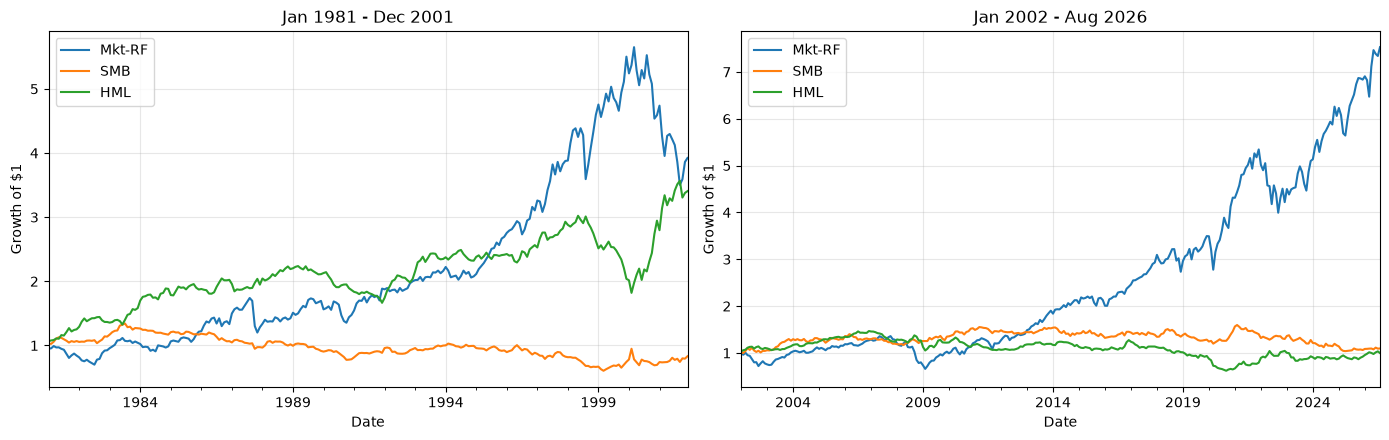

In [4]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, (name, (s, e)) in zip(axes, list(subsamples.items())[1:]):
    (1 + F.loc[s:e]).cumprod().plot(ax=ax, title=name)
    ax.set_ylabel("Growth of $1")
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Section 2.5 - Q&As

In [5]:
cum_ret = {name: (1 + F.loc[s:e]).prod() - 1 for name, (s, e) in list(subsamples.items())[1:]}
pd.DataFrame(cum_ret)

,Jan 1981 - Dec 2001,Jan 2002 - Aug 2026
Mkt-RF,2.922672,6.528388
SMB,-0.168807,0.096209
HML,2.405611,-0.002543


**1981-2001:** Looking at the plot and numbers from Section 2.1, Mkt-RF and HML were clearly valuable as they both had upward growth and positive ann. mean and ann. Sharpe. SMB was not as much. Looking at the graph, it ended below where it started and (from section 2.1) with a negative mean and a Sharpe near zero.

**Post-2001:** Mkt-RF is by far the strongest. SMB is only slightly positive (Sharpe about 0.09). HML is flat to slightly negative, so the value premium has effectively vanished.

**Advice:** DFA should keep the market exposure, which is just owning equities. The size and value factors have not been rewarded to the same extent, so I would not advise emphasizing all three equally. One caveat is that the premia are noisy over 20-year windows, and the 1981-2001 value premium and the post-2001 drought could both be sample noise. I would advise DFA to keep the mkt exposure and a modest value tilt, while recognizing that size is the weakest of the three.

# Section 3.1 - Summary Statistics (Jan 1981 - Aug 2026)

In [8]:
ports = pd.read_excel(path, sheet_name="portfolios (total returns)")
ports[ports.columns[0]] = pd.to_datetime(ports[ports.columns[0]].astype(str), format="mixed")
ports = ports.set_index(ports.columns[0]).sort_index()

start, end = "1981-01-01", "2026-08-31"
rf = factors["RF"].loc[start:end]
R = ports.loc[start:end].sub(rf, axis=0)   # excess returns
Fs = F.loc[start:end]

port_stats = perf_stats(R)
port_stats

,Ann. Mean,Ann. Vol,Ann. Sharpe,VaR(.05)
SMALL LoBM,0.016273,0.271086,0.060029,-0.122570
ME1 BM2,0.092770,0.234308,0.395931,-0.095698
ME1 BM3,0.096150,0.200265,0.480116,-0.084358
ME1 BM4,0.116836,0.192610,0.606595,-0.077191
SMALL HiBM,0.130484,0.206658,0.631400,-0.087234
ME2 BM1,0.066131,0.243657,0.271410,-0.102520
ME2 BM2,0.105137,0.204877,0.513170,-0.083454
ME2 BM3,0.110990,0.186413,0.595400,-0.079006
ME2 BM4,0.109729,0.180984,0.606293,-0.075018
ME2 BM5,0.116058,0.212351,0.546539,-0.092439


# Section 3.2 - CAPM

In [ ]:
mkt = Fs["Mkt-RF"]
rows = {}
for c in R.columns:
    y = R[c]
    beta = np.cov(y, mkt, ddof=1)[0, 1] / mkt.var()
    alpha = y.mean() - beta * mkt.mean()
    resid = y - alpha - beta * mkt
    rows[c] = {
        "alpha (monthly)": alpha,
        "beta": beta,
        "Treynor": y.mean() * 12 / beta,
        "Info Ratio": alpha * 12 / (resid.std() * np.sqrt(12)),
    }
capm = pd.DataFrame(rows).T
MAE = capm["alpha (monthly)"].abs().mean()
print(f"CAPM MAE: {MAE:.5f}  (annualized: {MAE*12:.4f})")
capm

CAPM MAE (monthly alpha): 0.00185  (annualized: 0.0222)


,alpha (monthly),beta,Treynor,Info Ratio
SMALL LoBM,-0.008475,1.364180,0.011929,-0.596891
ME1 BM2,-0.000627,1.159707,0.079994,-0.049837
ME1 BM3,0.000465,1.047256,0.091812,0.047360
ME1 BM4,0.002763,0.967590,0.120749,0.273194
SMALL HiBM,0.003753,0.988031,0.132065,0.323479
ME2 BM1,-0.004103,1.333986,0.049574,-0.379173
ME2 BM2,0.000579,1.135460,0.092594,0.065682
ME2 BM3,0.001777,1.036788,0.107052,0.223959
ME2 BM4,0.002171,0.967634,0.113400,0.255590
ME2 BM5,0.001735,1.101240,0.105389,0.164007


Treynor ratio: mean 0.0938, std 0.0250 (market's own Treynor = mkt ann. mean = 0.0865)


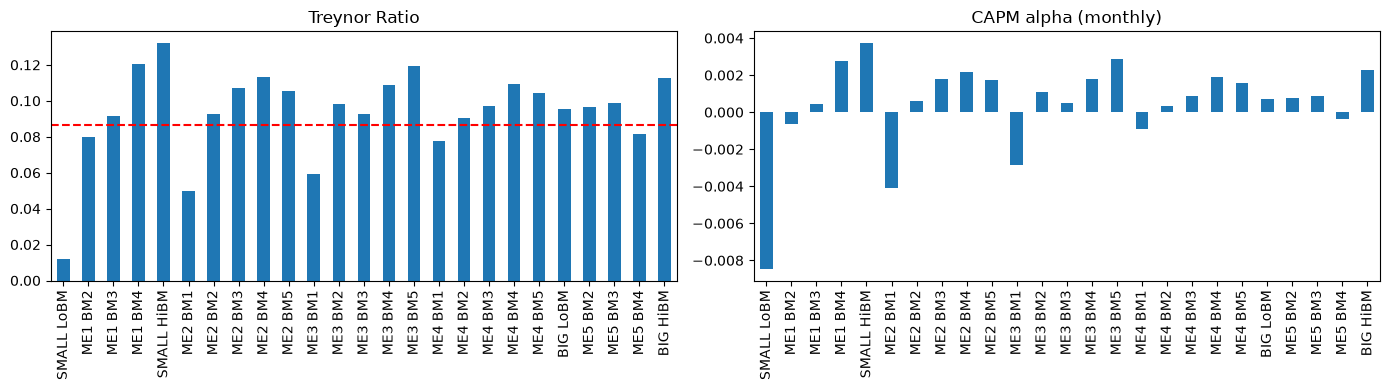

In [8]:
print("Treynor ratio: mean %.4f, std %.4f (market's own Treynor = mkt ann. mean = %.4f)" % (capm["Treynor"].mean(), capm["Treynor"].std(), mkt.mean()*12))
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
capm["Treynor"].plot.bar(ax=ax[0], title="Treynor Ratio"); ax[0].axhline(mkt.mean()*12, color="r", ls="--")
capm["alpha (monthly)"].plot.bar(ax=ax[1], title="CAPM alpha (monthly)")
plt.tight_layout(); plt.show()

**Treynor, alpha, IR under the CAPM:** If the CAPM were true, every portfolio's Treynor ratio (mean excess return / beta) would equal the market's excess return and be the same. All alphas would be 0, and so would all Information Ratios (alpha / residual vol). Instead Treynor ranges from about 1% (SMALL LoBM) to about 13% (SMALL HiBM), and IRs range from about -0.60 to +0.32.